# 01 — Data Exploration: NASA C-MAPSS FD001

**Goal:** load training trajectories, inspect structure and data quality, and record evidence-based observations. Run cells from top to bottom. Do not write conclusions before inspecting outputs.

## 1. Imports and paths

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 30)
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"
TRAIN_PATH = DATA_DIR / "train_FD001.txt"

print("Training file:", TRAIN_PATH)
print("File exists:", TRAIN_PATH.exists())

Training file: C:\Users\Hp\OneDrive\Bureau\MLproject\predictive-maintenance-ml\data\raw\train_FD001.txt
File exists: True


## 2. Define column names
Each row contains an engine ID, cycle number, three operating settings, and 21 sensor measurements.

In [5]:
columns = ["unit", "cycle", "setting_1", "setting_2", "setting_3"] + [
    f"sensor_{i}" for i in range(1, 22)
]
len(columns), columns

(26,
 ['unit',
  'cycle',
  'setting_1',
  'setting_2',
  'setting_3',
  'sensor_1',
  'sensor_2',
  'sensor_3',
  'sensor_4',
  'sensor_5',
  'sensor_6',
  'sensor_7',
  'sensor_8',
  'sensor_9',
  'sensor_10',
  'sensor_11',
  'sensor_12',
  'sensor_13',
  'sensor_14',
  'sensor_15',
  'sensor_16',
  'sensor_17',
  'sensor_18',
  'sensor_19',
  'sensor_20',
  'sensor_21'])

## 3. Load the training data
If the file-exists check above was False, review the README folder instructions.

In [6]:
train = pd.read_csv(
    TRAIN_PATH,
    sep=r"\s+",
    header=None,
    names=columns
)
train.head()

,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [7]:
last_cycle = train.groupby("unit")["cycle"].max()

train["RUL"] = (
    train["unit"].map(last_cycle) - train["cycle"]
)
train[
    ["unit", "cycle", "RUL"]
].head(10)

,unit,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187
5,1,6,186
6,1,7,185
7,1,8,184
8,1,9,183
9,1,10,182


In [8]:
# Check the RUL values
print("Missing RUL values:", train["RUL"].isna().sum())
print("Minimum RUL:", train["RUL"].min())
print("Maximum RUL:", train["RUL"].max())

# Every engine should have RUL = 0 at its final observed cycle
final_rows = train.loc[
    train.groupby("unit")["cycle"].idxmax()
]

print("All final RUL values are zero:",
      (final_rows["RUL"] == 0).all())

Missing RUL values: 0
Minimum RUL: 0
Maximum RUL: 361
All final RUL values are zero: True


## 4. Basic dimensions and data types

In [9]:
print("Shape (rows, columns):", train.shape)
print("Unique engines:", train["unit"].nunique())
print("Maximum cycle number:", train["cycle"].max())
display(train.dtypes)

Shape (rows, columns): (20631, 27)
Unique engines: 100
Maximum cycle number: 362


unit           int64
cycle          int64
setting_1    float64
setting_2    float64
setting_3    float64
sensor_1     float64
sensor_2     float64
sensor_3     float64
sensor_4     float64
sensor_5     float64
sensor_6     float64
sensor_7     float64
sensor_8     float64
sensor_9     float64
sensor_10    float64
sensor_11    float64
sensor_12    float64
sensor_13    float64
sensor_14    float64
sensor_15    float64
sensor_16    float64
sensor_17      int64
sensor_18      int64
sensor_19    float64
sensor_20    float64
sensor_21    float64
RUL            int64
dtype: object

## 5. Data quality checks

In [10]:
print("Missing values per column:")
display(train.isna().sum().to_frame("missing_values"))
print("Duplicate rows:", train.duplicated().sum())
display(train.describe().T)

Missing values per column:


,missing_values
unit,0
cycle,0
setting_1,0
setting_2,0
setting_3,0
sensor_1,0
sensor_2,0
sensor_3,0
sensor_4,0
sensor_5,0


Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
unit,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200


## 6. How long is each engine's observed trajectory?

,min,max,count
unit,,,
1,1,192,192
2,1,287,287
3,1,179,179
4,1,189,189
5,1,269,269
6,1,188,188
7,1,259,259
8,1,150,150
9,1,201,201


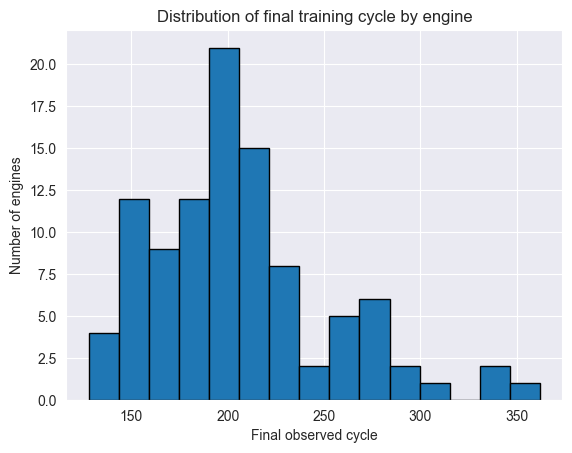

In [11]:
cycle_counts = train.groupby("unit")["cycle"].agg(["min", "max", "count"])
display(cycle_counts.head(10))
ax = cycle_counts["max"].plot(kind="hist", bins=15, edgecolor="black")
ax.set_title("Distribution of final training cycle by engine")
ax.set_xlabel("Final observed cycle")
ax.set_ylabel("Number of engines")
plt.show()

## 7. Constant and near-constant sensors
This is a diagnostic, not an automatic instruction to drop columns.

In [12]:
sensor_cols = [c for c in train.columns if c.startswith("sensor_")]
sensor_summary = pd.DataFrame({
    "n_unique": train[sensor_cols].nunique(),
    "std": train[sensor_cols].std(),
    "min": train[sensor_cols].min(),
    "max": train[sensor_cols].max(),
}).sort_values(["n_unique", "std"])
display(sensor_summary)

,n_unique,std,min,max
sensor_1,1,0.000000e+00,518.6700,518.6700
sensor_10,1,0.000000e+00,1.3000,1.3000
sensor_18,1,0.000000e+00,2388.0000,2388.0000
sensor_19,1,0.000000e+00,100.0000,100.0000
sensor_16,1,3.469531e-18,0.0300,0.0300
sensor_5,1,5.329200e-15,14.6200,14.6200
sensor_6,2,1.388985e-03,21.6000,21.6100
sensor_17,13,1.548763e+00,388.0000,400.0000
sensor_8,53,7.098548e-02,2387.9000,2388.5600
sensor_13,56,7.191892e-02,2387.8800,2388.5600


## 8. Plot selected sensors for one engine

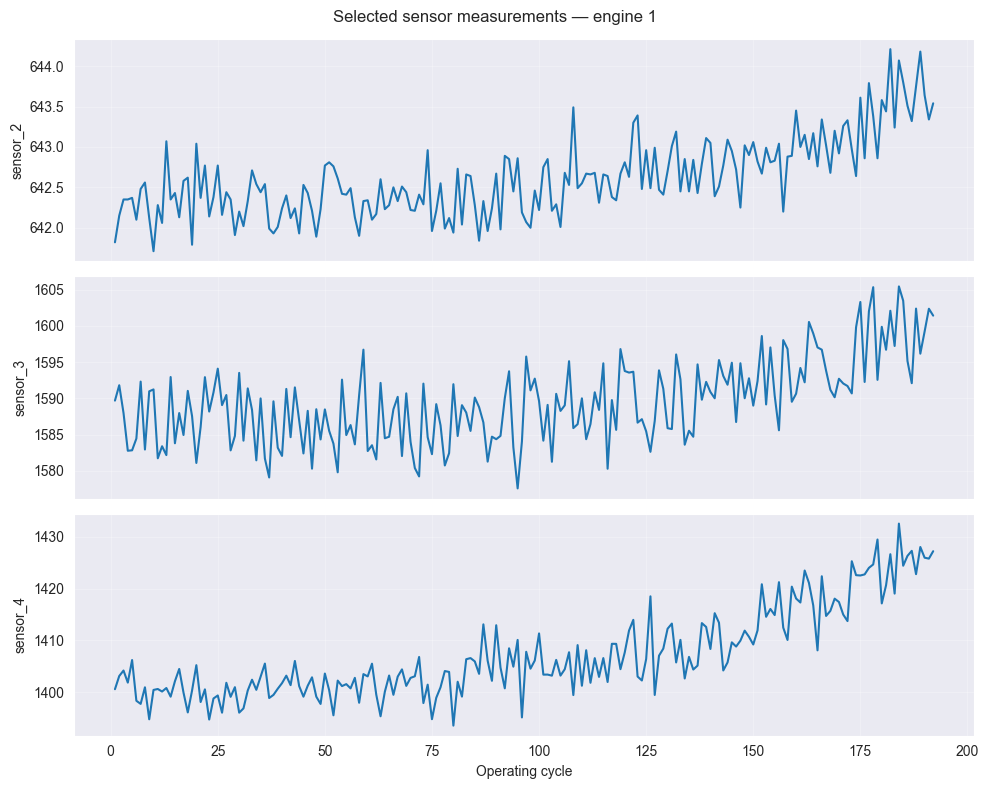

In [13]:
engine_id = 1
engine = train.loc[train["unit"] == engine_id].sort_values("cycle")
sensors_to_plot = ["sensor_2", "sensor_3", "sensor_4"]
fig, axes = plt.subplots(len(sensors_to_plot), 1, figsize=(10, 8), sharex=True)
for ax, sensor in zip(axes, sensors_to_plot):
    ax.plot(engine["cycle"], engine[sensor], linewidth=1.5)
    ax.set_ylabel(sensor)
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("Operating cycle")
fig.suptitle(f"Selected sensor measurements — engine {engine_id}")
plt.tight_layout()
plt.show()

### Sensor Behavior: Engine Unit 1

Sensors 2, 3, and 4 were plotted against operating cycles for engine unit 1 to investigate how their measurements evolve over time.

The observed trajectories suggest that sensor measurements may be associated with the engine's progression through its operating life. Since Remaining Useful Life (RUL) decreases as the operating cycle count increases, trends in sensor measurements may provide useful information for RUL estimation.

However, this observation is based on a single engine trajectory. Further analysis across multiple engines is required to determine whether these patterns are consistent and whether the relationships are linear, nonlinear, or weak.


count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64


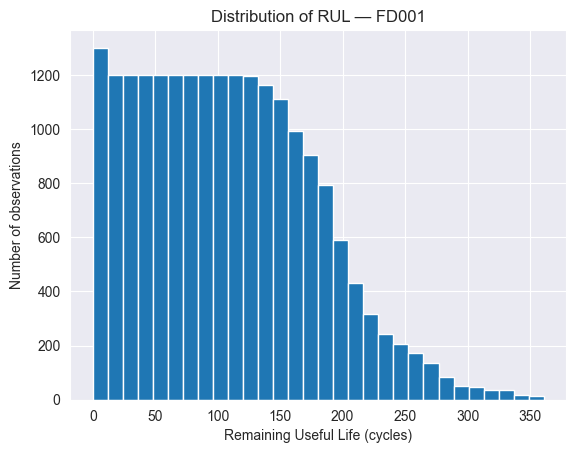

In [14]:
# Inspect the RUL distribution
print(train["RUL"].describe())

# Plot the distribution
import matplotlib.pyplot as plt

train["RUL"].hist(bins=30)
plt.xlabel("Remaining Useful Life (cycles)")
plt.ylabel("Number of observations")
plt.title("Distribution of RUL — FD001")
plt.show()

In [15]:
bins = [0, 25, 50, 75, 100, 125, 150, 200, float("inf")]

train["RUL_range"] = pd.cut(train["RUL"], bins=bins)

print(train["RUL_range"].value_counts().sort_index())

RUL_range
(0.0, 25.0]       2500
(25.0, 50.0]      2500
(50.0, 75.0]      2500
(75.0, 100.0]     2500
(100.0, 125.0]    2500
(125.0, 150.0]    2424
(150.0, 200.0]    3649
(200.0, inf]      1958
Name: count, dtype: int64


## 9. Findings — complete after running the notebook

- Number of rows and columns:
- Number of unique engines:
- Minimum and maximum final cycle across engines:
- Missing values or duplicate rows:
- Sensors that appear constant or nearly constant:
- One pattern you noticed in the plots:
- One question to investigate next:

### Reflection
What can this simulated dataset tell us, and what can it not tell us? A visible trend alone does not prove a sensor is useful for prediction.

,correlation_with_RUL
sensor_11,-0.696228
sensor_4,-0.678948
sensor_15,-0.642667
sensor_2,-0.606484
sensor_17,-0.606154
sensor_3,-0.584520
sensor_8,-0.563968
sensor_13,-0.562569
sensor_9,-0.390102
sensor_14,-0.306769


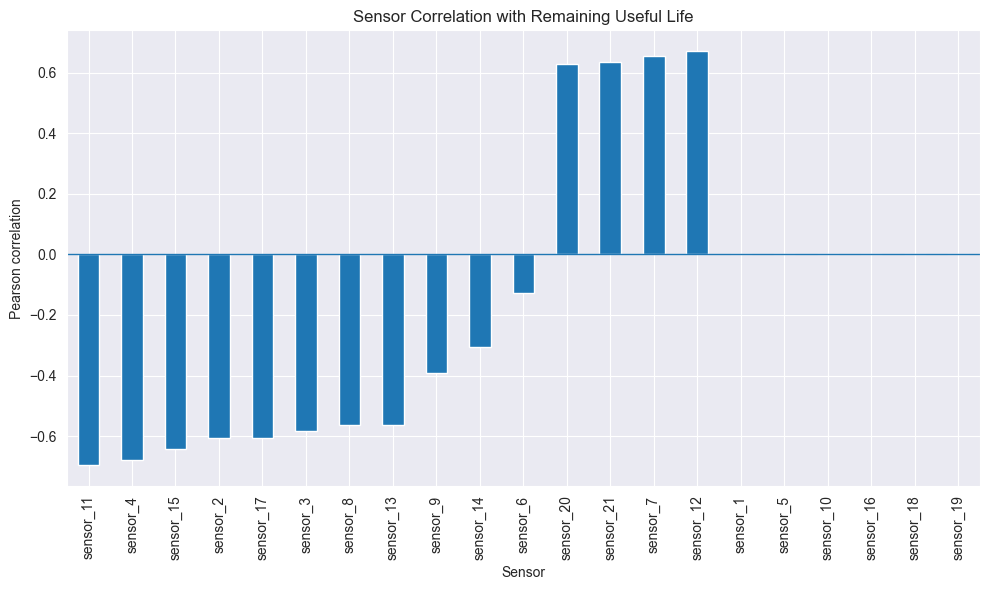

In [16]:
# Correlation between each sensor and RUL
sensor_rul_corr = (
    train[sensor_cols + ["RUL"]]
    .corr(numeric_only=True)["RUL"]
    .drop("RUL")
    .sort_values()
)

display(sensor_rul_corr.to_frame("correlation_with_RUL"))

# Visualize the correlations
plt.figure(figsize=(10, 6))
sensor_rul_corr.plot(kind="bar")
plt.axhline(0, linewidth=1)
plt.title("Sensor Correlation with Remaining Useful Life")
plt.ylabel("Pearson correlation")
plt.xlabel("Sensor")
plt.tight_layout()
plt.show()

### Sensor Correlation with Remaining Useful Life

Pearson correlation analysis revealed different relationships between sensor readings and Remaining Useful Life (RUL). Sensors 11, 4, 15, 2, and 17 showed the strongest negative correlations, while sensors 12, 7, 21, and 20 showed the strongest positive correlations.

These results suggest that several sensor measurements may be informative for RUL estimation. Other sensors showed correlations close to zero, indicating little linear association with RUL in this analysis.

These findings are preliminary. The correlations do not establish causation or prove that a sensor will improve model performance. Because multiple observations come from each engine, further analysis and engine-level evaluation are needed before selecting features for a predictive model.


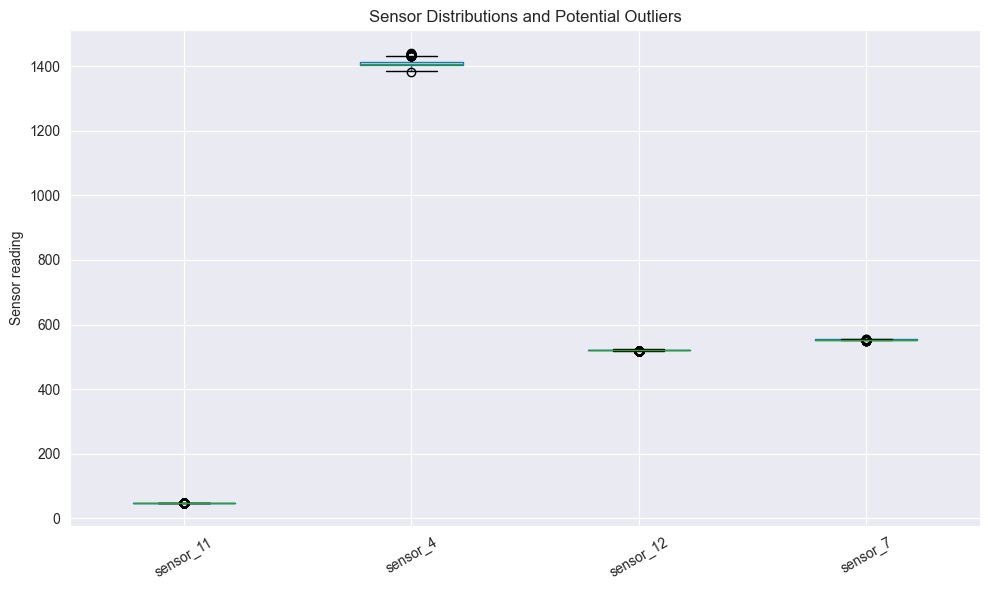

In [18]:
# Boxplots for a few sensors with stronger correlations
selected_sensors = [
    "sensor_11",
    "sensor_4",
    "sensor_12",
    "sensor_7"
]

plt.figure(figsize=(10, 6))
train[selected_sensors].boxplot()
plt.title("Sensor Distributions and Potential Outliers")
plt.ylabel("Sensor reading")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,sensor_11,sensor_12
RUL_group,,
0–25,47.991,520.215
26–50,47.734,520.887
51–75,47.589,521.290
76–100,47.497,521.542
100+,47.383,521.833


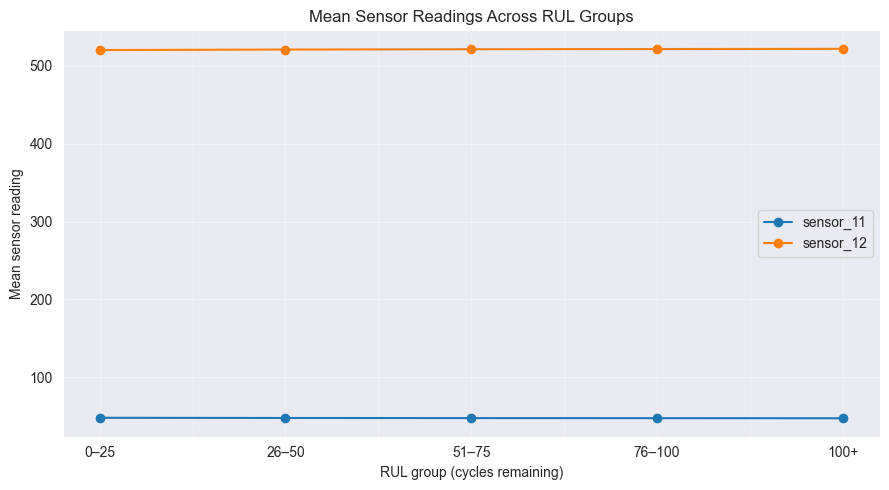

In [19]:
# Divide observations into broad RUL groups
train["RUL_group"] = pd.cut(
    train["RUL"],
    bins=[-1, 25, 50, 75, 100, float("inf")],
    labels=["0–25", "26–50", "51–75", "76–100", "100+"]
)

# Compare sensor readings across RUL groups
display(
    train.groupby("RUL_group", observed=False)[
        ["sensor_11", "sensor_12"]
    ].mean().round(3)
)
train.groupby("RUL_group", observed=False)[
    ["sensor_11", "sensor_12"]
].mean().plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

plt.title("Mean Sensor Readings Across RUL Groups")
plt.xlabel("RUL group (cycles remaining)")
plt.ylabel("Mean sensor reading")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Sensor Behavior Across RUL Groups

Mean sensor readings were compared across five RUL groups. Sensor 11 showed a gradual decrease in its mean value from 47.991 in the 0–25 RUL group to 47.383 in the 100+ group. In contrast, sensor 12 showed a gradual increase from 520.215 to 521.833 across the same groups.

These trends are consistent with the negative correlation observed between sensor 11 and RUL and the positive correlation observed between sensor 12 and RUL. However, the changes in mean readings are relatively small, and group averages do not show the full variability of individual observations. Further analysis is needed to determine how informative these sensors are for prediction.


In [20]:
rul_group_summary = train.groupby(
    "RUL_group", observed=False
)[["sensor_11", "sensor_12"]].agg(
    ["mean", "std", "median", "min", "max"]
).round(3)

display(rul_group_summary)

sensor_11                             sensor_12                 \
               mean    std median    min    max      mean    std  median   
RUL_group                                                                  
0–25         47.991  0.158  48.00  47.43  48.53   520.215  0.478  520.20   
26–50        47.734  0.156  47.73  47.22  48.21   520.887  0.456  520.88   
51–75        47.589  0.161  47.59  47.05  48.06   521.290  0.462  521.30   
76–100       47.497  0.166  47.50  46.97  48.00   521.542  0.478  521.54   
100+         47.383  0.174  47.38  46.85  47.91   521.833  0.501  521.84   

                           
              min     max  
RUL_group                  
0–25       518.69  521.66  
26–50      519.43  522.89  
51–75      519.82  522.72  
76–100     519.89  522.76  
100+       520.19  523.38

### Variability Across RUL Groups

The standard deviations reported for sensors 11 and 12 were approximately 0.45–0.50 across the RUL groups. Their mean readings changed gradually across groups, but the differences between neighboring groups were relatively small compared with the overall changes across the full RUL range. This suggests that group averages alone may not fully distinguish individual observations by RUL. Further evaluation using engine-level validation is required to determine the sensors' predictive usefulness.


In [21]:
print("Number of engines:", train["unit"].nunique())
print("Number of rows:", len(train))
print("RUL range:", train["RUL"].min(), "to", train["RUL"].max())

Number of engines: 100
Number of rows: 20631
RUL range: 0 to 361
